# Question 3: Topic Analysis - Research Document Mining

Flow: build the articles data frame (3.1), preprocess (3.2), summarise article 1 with a frequency-based extractive method (3.3), summarise articles 2 to 5 as an aggregate with TextRank (3.4).

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import nltk
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize

## 3.1 Data frame of articles and their content

In [2]:
rows = []
for f in sorted(glob.glob('../data/research_corpus/research_*.txt')):
    with open(f, encoding='utf-8', errors='ignore') as fh:
        rows.append({'article': os.path.basename(f), 'content': fh.read()})
df_articles = pd.DataFrame(rows)
print(df_articles.shape)
df_articles.head()

(5, 2)


,article,content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


## 3.2 Preprocessing the article content

Steps: normalise whitespace and line breaks; remove URLs and e-mail addresses; remove in-text citations such as `(Smith, 2015)` and `[12]`; lowercase; keep letters only; remove NLTK English stop words; drop 1 to 2 letter tokens; **lemmatise** with WordNet (for example "studies" becomes "study") so different forms of a word count together.

In [3]:
STOP = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+|\S+@\S+', ' ', text)
    text = re.sub(r'\([^()]*\b(?:19|20)\d{2}[a-z]?\b[^()]*\)', ' ', text)   # (Author, 2015)
    text = re.sub(r'\[\d+(?:[,\s\u2013-]+\d+)*\]', ' ', text)               # [12], [3-5]
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return [lemmatizer.lemmatize(t) for t in text.split() if t not in STOP and len(t) > 2]

df_articles['tokens'] = df_articles['content'].apply(preprocess)
df_articles['clean'] = df_articles['tokens'].apply(' '.join)
df_articles['words_raw'] = df_articles['content'].str.split().str.len()
df_articles['words_clean'] = df_articles['tokens'].str.len()
df_articles[['article', 'words_raw', 'words_clean']]

,article,words_raw,words_clean
0,research_1.txt,5602,3038
1,research_2.txt,2416,1202
2,research_3.txt,3828,2101
3,research_4.txt,5922,3184
4,research_5.txt,4027,2171


In [4]:
print('RAW  :', re.sub(r'\s+', ' ', df_articles['content'][0])[:400])
print()
print('CLEAN:', df_articles['clean'][0][:400])

RAW  : The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradig

CLEAN: purpose article position mixed method research mixed research synonym natural complement traditional qualitative quantitative research present pragmatism offering attractive philosophical partner mixed method research provide framework designing conducting mixed method research briefly review paradigm war incompatibility thesis show commonality quantitative qualitative research explain tenet pragm


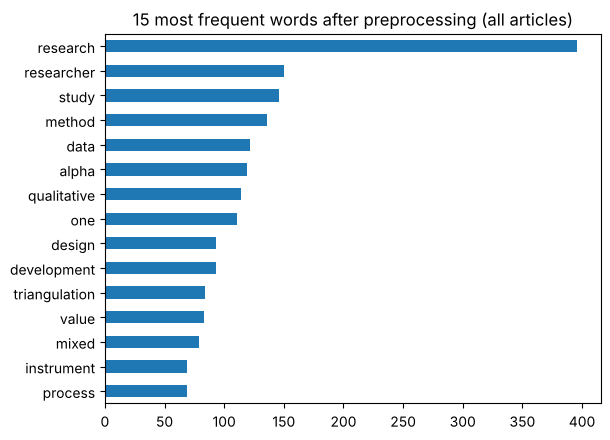

In [5]:
top = Counter(w for toks in df_articles['tokens'] for w in toks).most_common(15)
pd.Series(dict(top)).sort_values().plot(kind='barh', title='15 most frequent words after preprocessing (all articles)')
plt.show()

## 3.3 Summarising the first article (frequency-based extractive summarisation)

Method: score each sentence by the importance of the words it contains (word frequencies from the preprocessed article, normalised by the most frequent word), divided by the square root of the sentence length so long sentences are not favoured. The 5 top-scoring sentences are kept in their original order.

In [6]:
def get_sentences(text, min_words=8, max_words=60):
    text = re.sub(r'\s+', ' ', text)
    sents = sent_tokenize(text)
    out, seen = [], set()
    for s in sents:
        n = len(s.split())
        digits = sum(c.isdigit() for c in s) / max(len(s), 1)
        low = s.lower()
        if 'keywords:' in low or 'journal of' in low:   # page headers / keyword lines
            continue
        if min_words <= n <= max_words and digits < 0.1 and low not in seen:   # skip repeated sentences
            seen.add(low)
            out.append(s.strip())
    return out

art1 = df_articles.loc[0, 'content']
sents1 = get_sentences(art1)
freq = Counter(df_articles.loc[0, 'tokens'])
max_f = max(freq.values())
norm = {w: c / max_f for w, c in freq.items()}

def score(s):
    toks = preprocess(s)
    return sum(norm.get(t, 0) for t in toks) / np.sqrt(max(len(toks), 1))

scores1 = np.array([score(s) for s in sents1])
top_idx = sorted(np.argsort(scores1)[::-1][:5])
print(f'{len(sents1)} candidate sentences; summary:')
summary1 = ' '.join(sents1[i] for i in top_idx)
print(summary1)
print(f'\nCompression: {len(art1.split())} words -> {len(summary1.split())} words')

72 candidate sentences; summary:
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research (Onwuegbuzie & Leech, 2004a). We contend that researchers and research methodologists need to be asking when each research approach is most help

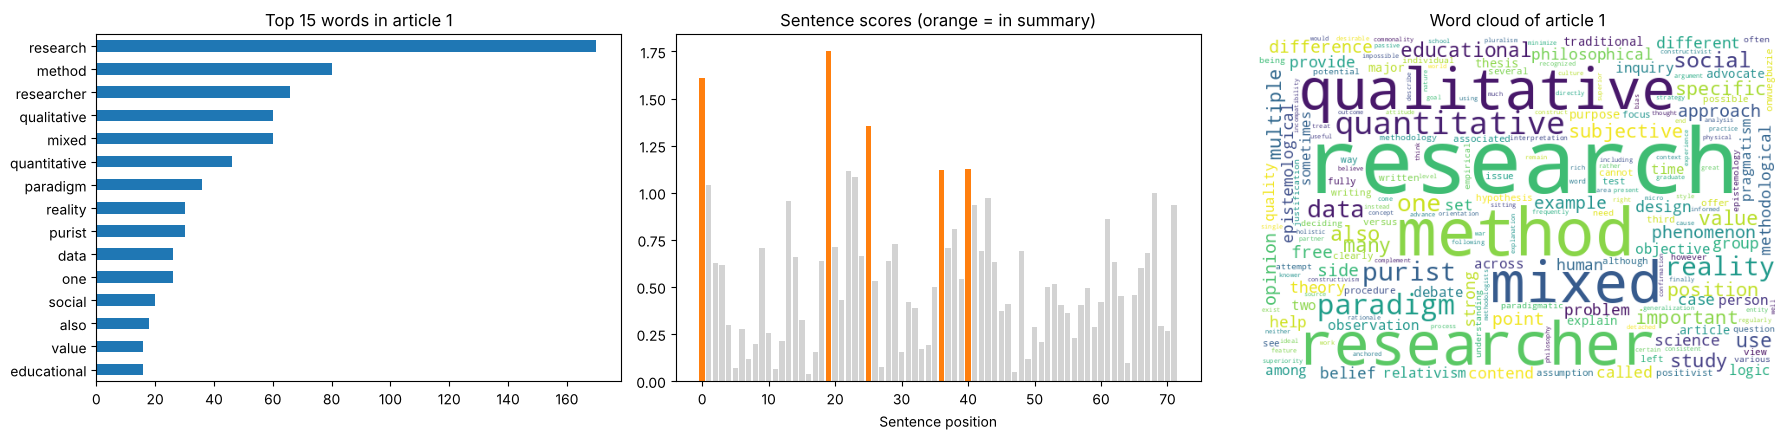

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) key words
top_words = pd.Series(dict(freq.most_common(15))).sort_values()
top_words.plot(kind='barh', ax=axes[0], title='Top 15 words in article 1')

# (b) sentence scores with the chosen sentences highlighted
colors = ['tab:orange' if i in top_idx else 'lightgrey' for i in range(len(scores1))]
axes[1].bar(range(len(scores1)), scores1, color=colors)
axes[1].set_title('Sentence scores (orange = in summary)'); axes[1].set_xlabel('Sentence position')

# (c) word cloud
axes[2].imshow(WordCloud(width=600, height=400, background_color='white').generate_from_frequencies(freq))
axes[2].axis('off'); axes[2].set_title('Word cloud of article 1')
plt.tight_layout(); plt.show()

## 3.4 Aggregate summary of articles 2 to 5 (TextRank)

A different technique from 3.3: **TextRank**. All sentences from articles 2 to 5 are pooled. Each sentence is a node in a graph, edges are weighted by the cosine similarity of the sentences' TF-IDF vectors, and PageRank ranks the sentences. Highly ranked sentences are the ones most connected to the rest of the corpus. The two best-ranked sentences of each article are kept, so the aggregate summary covers all four articles.

In [8]:
pool = []
for _, r in df_articles.iloc[1:].iterrows():
    for pos, s in enumerate(get_sentences(r['content'])):
        pool.append({'article': r['article'], 'pos': pos, 'sentence': s, 'clean': ' '.join(preprocess(s))})
pool = pd.DataFrame(pool)
pool = pool[pool['clean'].str.split().str.len() >= 4].reset_index(drop=True)
print(pool.shape); print(pool['article'].value_counts().sort_index())

(504, 4)
article
research_2.txt     48
research_3.txt    151
research_4.txt    162
research_5.txt    143
Name: count, dtype: int64


In [9]:
vec = TfidfVectorizer()
S = vec.fit_transform(pool['clean'])
sim = cosine_similarity(S)
np.fill_diagonal(sim, 0)
graph = nx.from_numpy_array(sim)
pr = nx.pagerank(graph, weight='weight')
pool['textrank'] = pd.Series(pr)

# keep the 2 best sentences of each article so every article is represented in the aggregate summary
top = pool.sort_values('textrank', ascending=False).groupby('article').head(2)
summary = top.sort_values(['article', 'pos'])
for _, r in summary.iterrows():
    print(f"[{r['article']}] {r['sentence']}\n")

[research_2.txt] (p. 309) One goal of reflexivity in qualitative research is to monitor such effects and thus enhance the accuracy of the research and ‘the credibility of the findings by accounting for researcher values, beliefs, knowledge, and biases’ (Cutcliffe, 2003: 137), that is, to gain plausibility by securing research’s trustworthiness (Buckner, 2005; Macbeth, 2001).

[research_2.txt] Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions (Bradbury-Jones, 2007; Guillemin and Gillam, 2004).

[research_3.txt] Early research methods texts addressed development as the “research and development” process (Borg & Gall, 1971).

[research_3.txt] Other studies in this category focus on only one phase of the design/development/evaluation process, such as Jonassen’s (1988) case study of using needs assessment data in the development of a university program.

[research_4

### Visualisations for the aggregate summary

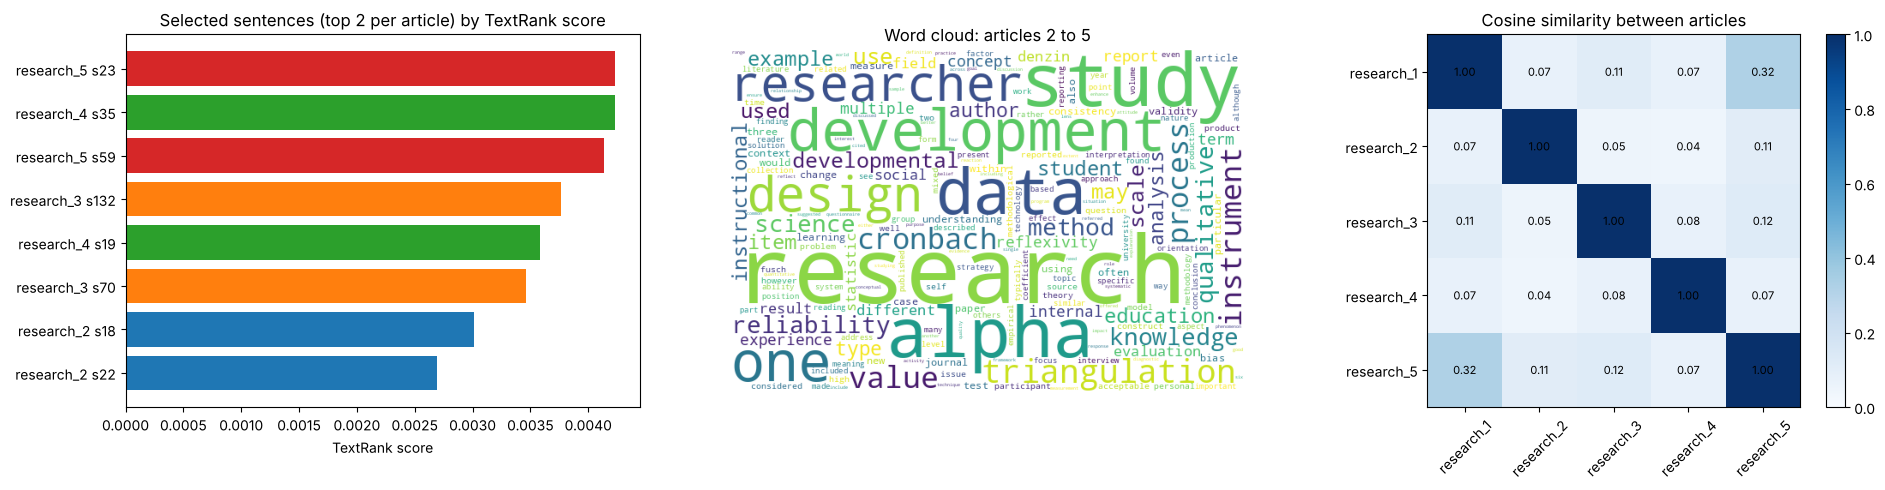

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (a) TextRank scores of the selected sentences, coloured by article
color_map = {a: c for a, c in zip(sorted(pool['article'].unique()), ['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])}
t = top.sort_values('textrank')
axes[0].barh([f"{a.split('.')[0]} s{p}" for a, p in zip(t['article'], t['pos'])], t['textrank'],
             color=[color_map[a] for a in t['article']])
axes[0].set_title('Selected sentences (top 2 per article) by TextRank score'); axes[0].set_xlabel('TextRank score')

# (b) word cloud of the aggregate corpus
agg_freq = Counter(w for toks in df_articles.iloc[1:]['tokens'] for w in toks)
axes[1].imshow(WordCloud(width=600, height=400, background_color='white').generate_from_frequencies(agg_freq))
axes[1].axis('off'); axes[1].set_title('Word cloud: articles 2 to 5')

# (c) similarity between the articles
tv = TfidfVectorizer(max_df=0.9)
A = tv.fit_transform(df_articles['clean'])
sim_art = cosine_similarity(A)
im = axes[2].imshow(sim_art, cmap='Blues', vmin=0, vmax=1)
names = [a.split('.')[0] for a in df_articles['article']]
axes[2].set_xticks(range(5)); axes[2].set_xticklabels(names, rotation=45)
axes[2].set_yticks(range(5)); axes[2].set_yticklabels(names)
for i in range(5):
    for j in range(5):
        axes[2].text(j, i, f'{sim_art[i, j]:.2f}', ha='center', va='center', fontsize=8)
axes[2].set_title('Cosine similarity between articles'); plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

In [11]:
# Top TF-IDF terms for each remaining article (what makes each one distinctive)
terms = np.array(tv.get_feature_names_out())
for i in range(1, 5):
    idx = A[i].toarray().ravel().argsort()[::-1][:8]
    print(df_articles.loc[i, 'article'], '->', ', '.join(terms[idx]))

research_2.txt -> reflexivity, personal, participant, woman, position, immigration, immigrant, self
research_3.txt -> development, developmental, instructional, design, evaluation, product, model, system
research_4.txt -> alpha, cronbach, scale, instrument, reliability, item, statistic, science
research_5.txt -> triangulation, denzin, method, design, fusch, mixed, multiple, source


### Comment

The two methods suit different jobs. The frequency method (3.3) is simple and works well for one article with a single focus. TextRank (3.4) pools several articles and favours sentences that share vocabulary with many others, so it picks sentences that state each article's central concept (reflexivity, instructional design research, Cronbach's alpha, triangulation) in terms shared with the rest of the corpus. The similarity heatmap shows this: the articles share a research-methods theme but each also has its own distinctive terms (reflexivity, instructional design, Cronbach's alpha, triangulation).